<a href="https://colab.research.google.com/github/DancerDark777/chmura-cwiczenia/blob/main/Kopia_notatnika_Cwiczenia_02_Piec_zagadek_o_chmurze.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="background:linear-gradient(135deg,#3b0764 0%,#7c3aed 55%,#f59e0b 100%);padding:50px 36px;border-radius:18px;color:white;text-align:center">
<div style="font-size:56px">🕵️⚡🕊️</div>
<div style="font-size:15px;letter-spacing:4px;text-transform:uppercase;opacity:.85;margin-top:8px">Ćwiczenia 2 · do wykładu 2</div>
<div style="font-size:38px;font-weight:800;line-height:1.2;margin:10px 0">Pięć zagadek o chmurze</div>
<div style="font-size:19px;opacity:.92">Najpierw obstaw, potem sprawdź</div>
<div style="margin-top:22px;font-size:15px;opacity:.8">Wprowadzenie do przetwarzania w chmurze</div>
</div>

<div style="background:linear-gradient(120deg,#7c3aed,#c084fc);padding:20px 26px;border-radius:14px;color:white;margin-top:18px">
<div style="font-size:13px;letter-spacing:2px;text-transform:uppercase;opacity:.85">Organizacja</div>
<div style="font-size:27px;font-weight:700;line-height:1.25;margin-top:4px">Zasady gry</div>
</div>


Dzisiejsze ćwiczenia to pięć pytań, na które **każdy ma jakąś intuicję** — i pięć eksperymentów, które tę intuicję sprawdzą. Przy każdym pytaniu:

1. **🎯 Obstawiam** — proszę wpisać swoją odpowiedź *zanim* uruchomi się kod. Błędne obstawienie nie obniża oceny; brak obstawienia — tak.
2. **▶ Sprawdzam** — uruchomienie komórki z kodem.
3. **✍️ Odpowiedź** — kilka krótkich pytań o to, co wyszło i dlaczego.

Na końcu proszę policzyć, ile razy intuicja trafiła. Rekordziści zostaną wymienieni z imienia na następnych zajęciach.

| Nr | Zagadka | O czym naprawdę jest |
|:-:|---|---|
| **1** | 🕵️ Kto tu udaje komputer? | wirtualizacja i kontenery |
| **2** | 🏁 Kto szybszy: Twoje urządzenie czy Google? | moc obliczeniowa, język programowania |
| **3** | 🤹 Ilu pracowników naprawdę zatrudniliśmy? | wirtualne procesory (vCPU) i równoległość |
| **4** | ⚡ Czy Internet jest szybszy od światła? | regiony, opóźnienia, fizyka |
| **5** | 🕊️ Gołąb, samochód czy światłowód? | przepustowość a opóźnienie |

**Jak pracować z notatnikiem** — jak zawsze: *Plik → Zapisz kopię na Dysku*, komórki uruchamia się ▶ albo **Shift+Enter**, a komórki 🎯 i ✍️ uzupełnia się po dwukrotnym kliknięciu.

<div style="background:#eef6fc;border-left:6px solid #19a7ce;padding:12px 16px;border-radius:8px;color:#12303f;font-size:15px;margin:10px 0">📱 Zagadki 2 i 5 dają się wykonać nawet na telefonie. Pozostałe też zadziałają, ale wygodniej będzie na komputerze.</div><div style="background:#e6f4ea;border-left:6px solid #0f766e;padding:12px 16px;border-radius:8px;color:#12303f;font-size:15px;margin:10px 0">💳 Jak na ćwiczeniach 1: <b>nic się nie instaluje i nigdzie nie podaje się karty płatniczej</b>. Wystarczy konto Google.</div>

In [1]:
IMIE = "Dawid Bąk"
GRUPA = "1"
print(f"Zagadki rozwiązuje: {IMIE}, grupa {GRUPA}")

Zagadki rozwiązuje: Dawid Bąk, grupa 1


<div style="background:linear-gradient(120deg,#1e3a8a,#60a5fa);padding:20px 26px;border-radius:14px;color:white;margin-top:18px">
<div style="font-size:13px;letter-spacing:2px;text-transform:uppercase;opacity:.85">Zagadka 1 · wirtualizacja</div>
<div style="font-size:27px;font-weight:700;line-height:1.25;margin-top:4px">🕵️ Kto tu udaje komputer?</div>
</div>


Na wykładzie 2 będzie mowa o tym, że maszyna wirtualna „udaje” prawdziwy komputer tak dobrze, że system operacyjny w środku może się nie zorientować. Ale czy na pewno nie zostawia **poszlak**? Proszę wcielić się w detektywa.

**🎯 Obstawiam** *(proszę uzupełnić **przed** uruchomieniem kodu — bez zaglądania do odpowiedzi!)*

1. Czy maszyna, na której działa ten notatnik, to prawdziwy, fizyczny komputer, maszyna wirtualna, czy coś jeszcze innego? maszyna wirtualna
2. Ile poszlak zdradzających wirtualizację znajdzie śledztwo (0–6)? 4

In [2]:
import pathlib, subprocess, os

def czytaj(sciezka):
    try:
        return pathlib.Path(sciezka).read_text().strip() or "(pusto)"
    except Exception:
        return "(brak dostępu — świadek milczy)"

def polecenie(p):
    return subprocess.run(p, shell=True, capture_output=True, text=True).stdout.strip() or "(brak wyniku)"

flagi = czytaj("/proc/cpuinfo")
model = next((w.split(":", 1)[1].strip() for w in flagi.splitlines() if w.startswith("model name")), "?")

poszlaki = [
    ("Producent komputera (tabliczka znamionowa)", czytaj("/sys/class/dmi/id/sys_vendor")),
    ("Nazwa modelu komputera",                      czytaj("/sys/class/dmi/id/product_name")),
    ("Procesor",                                    model),
    ("Czy procesor przyznaje się do nadzorcy?",     "TAK — flaga 'hypervisor'" if "hypervisor" in flagi else "nie"),
    ("Adres sprzętowy (MAC) karty sieciowej",       polecenie("cat /sys/class/net/*/address | grep -v 00:00:00:00:00:00 | head -1")),
    ("Proces nr 1 (na zwykłym Linuksie: systemd)",  polecenie("ps -p 1 -o comm=")),
]
for nr, (pytanie, odp) in enumerate(poszlaki, 1):
    print(f"🔎 Poszlaka {nr}. {pytanie}:\n      {odp}\n")

🔎 Poszlaka 1. Producent komputera (tabliczka znamionowa):
      Google

🔎 Poszlaka 2. Nazwa modelu komputera:
      Google Compute Engine

🔎 Poszlaka 3. Procesor:
      Intel(R) Xeon(R) CPU @ 2.20GHz

🔎 Poszlaka 4. Czy procesor przyznaje się do nadzorcy?:
      TAK — flaga 'hypervisor'

🔎 Poszlaka 5. Adres sprzętowy (MAC) karty sieciowej:
      02:42:ac:1c:00:0c

🔎 Poszlaka 6. Proces nr 1 (na zwykłym Linuksie: systemd):
      docker-init



**Ściągawka detektywa**

- Fizyczne komputery mają na tabliczce znamionowej nazwy w rodzaju *Dell*, *Lenovo*, *HP*.
- Flaga `hypervisor` to sygnał, który procesor wirtualny celowo wysyła do systemu: „jestem wirtualny, nadzorca czuwa”.
- Adres MAC, którego **druga cyfra** to `2`, `6`, `A` lub `E`, jest adresem **nadanym programowo**, a nie wytłoczonym fabrycznie w karcie. Adresy zaczynające się od `02:42` nadaje Docker.
- Jeżeli procesem nr 1 nie jest `systemd` ani `init`, jesteśmy najpewniej w **kontenerze** — małym, odizolowanym świecie, w którym „pierwszym” procesem jest to, co uruchomił jego twórca.

**✍️ Odpowiedź** *(proszę kliknąć dwukrotnie tę komórkę i uzupełnić)*

| Poszlaka | Co znaleziono | Czy zdradza wirtualizację lub kontener? |
|:-:|---|:-:|
| 1 | Producent Google | Tak |
| 2 | Model Google Compute Engine | Tak |
| 3 | Procesor Intel Xenon | Nie |
| 4 | Flaga hypervisor - TAK | Tak |
| 5 | Adres MAC - 02:42... | Tak, wskazuje na Docker |
| 6 | Proces nr 1 jest to inny proces niż systemd albo init | Tak, wskazuje na kontener |

1. Werdykt: na czym naprawdę działa ten notatnik? Proszę uzasadnić co najmniej dwiema poszlakami. Tak działa, pokazuje to Flaga hypervisor oraz Adres MAC
2. Jeżeli wyszło, że to kontener **wewnątrz** maszyny wirtualnej — ile warstw „udawania” dzieli Państwa kod od prawdziwego krzemu? Proszę je wymienić od dołu. Są to trzy wartswy: 1. Fizyczny serwer z procesorem. 2. Maszyna wirtualna zarządzana przez hypervisor. 3. Kontener Docker.
3. Dlaczego dostawca chmury w ogóle **zostawia** takie poszlaki, zamiast idealnie udawać fizyczny komputer? (Wskazówka: kto korzysta z flagi `hypervisor`?) Dostawca zostawia takie poszlaki ponieważ system i oprogramowanie mogą wykorzystywać informacje o wirtualizacji do optymalizacji, więc ukrywanie wszystkiego na 100% nie zawsze byłoby na plus.

<div style="background:linear-gradient(120deg,#b45309,#f59e0b);padding:20px 26px;border-radius:14px;color:white;margin-top:18px">
<div style="font-size:13px;letter-spacing:2px;text-transform:uppercase;opacity:.85">Zagadka 2 · moc obliczeniowa</div>
<div style="font-size:27px;font-weight:700;line-height:1.25;margin-top:4px">🏁 Kto szybszy: Twoje urządzenie czy Google?</div>
</div>


Wyścig: **ile jest liczb pierwszych mniejszych od 5 milionów?** Ścigają się trzej zawodnicy:

- 🐢 **Python „na piechotę”** na maszynie Google,
- 🚀 **Python z biblioteką NumPy** na maszynie Google,
- 📱 **JavaScript w Państwa przeglądarce** — czyli na Państwa telefonie lub laptopie, nie w chmurze!

Wszyscy używają tego samego, ponad dwutysiącletniego algorytmu: **sita Eratostenesa**.

**🎯 Obstawiam** *(proszę uzupełnić **przed** uruchomieniem kodu — bez zaglądania do odpowiedzi!)*

1. Kto wygra? Proszę ustawić zawodników w kolejności: 1. Python z NumPy. 2. Python. 3. JavaScript
2. Ile mniej więcej razy zwycięzca będzie szybszy od ostatniego? 5

In [3]:
import time, os, numpy as np
from IPython.display import HTML, display

N = 5_000_000

# --- Zawodnik 1: Python „na piechotę” ---
t0 = time.perf_counter()
sito = [True] * (N + 1); sito[0] = sito[1] = False; ile = 0
for i in range(2, N + 1):
    if sito[i]:
        ile += 1
        for j in range(i * i, N + 1, i):
            sito[j] = False
czas_python = time.perf_counter() - t0
print(f"🐢 Python na piechotę (Google): {ile} liczb pierwszych w {czas_python:.3f} s")

# --- Zawodnik 2: Python + NumPy ---
t0 = time.perf_counter()
s = np.ones(N + 1, dtype=bool); s[:2] = False
for i in range(2, int(N ** 0.5) + 1):
    if s[i]:
        s[i * i::i] = False
czas_numpy = time.perf_counter() - t0
print(f"🚀 Python + NumPy (Google):    {int(s.sum())} liczb pierwszych w {czas_numpy:.3f} s")
print(f"   Rdzenie procesora po stronie Google: {os.cpu_count()}")

# --- Zawodnik 3: JavaScript w Państwa przeglądarce ---
display(HTML(f"""
<div id="wynik-js" style="font-family:monospace;font-size:14px;margin-top:8px">📱 Liczę w Państwa przeglądarce…</div>
<script>
(function() {{
  const N = {N};
  const t0 = performance.now();
  const sito = new Uint8Array(N + 1); let ile = 0;
  for (let i = 2; i <= N; i++) {{
    if (!sito[i]) {{ ile++; for (let j = i * i; j <= N; j += i) sito[j] = 1; }}
  }}
  const t = (performance.now() - t0) / 1000;
  document.getElementById("wynik-js").innerHTML =
    "📱 JavaScript (Twoje urządzenie): " + ile + " liczb pierwszych w " + t.toFixed(3) + " s<br>" +
    "&nbsp;&nbsp;&nbsp;Rdzenie procesora Twojego urządzenia: " + navigator.hardwareConcurrency + "<br>" +
    "&nbsp;&nbsp;&nbsp;Przeglądarka: " + navigator.userAgent;
}})();
</script>"""))

🐢 Python na piechotę (Google): 348513 liczb pierwszych w 2.525 s
🚀 Python + NumPy (Google):    348513 liczb pierwszych w 0.021 s
   Rdzenie procesora po stronie Google: 2


**✍️ Odpowiedź** *(proszę kliknąć dwukrotnie tę komórkę i uzupełnić)*

| Zawodnik | Czas [s] | Miejsce |
|---|--:|:-:|
| 🐢 Python na piechotę (Google) | 2,525 | 3 |
| 🚀 Python + NumPy (Google) | 0,021 | 1 |
| 📱 JavaScript (moje urządzenie) | 0,098 | 2 |

1. Czy wszyscy trzej znaleźli **tę samą** liczbę liczb pierwszych? Jaką? Tak, znaleźli - liczbę liczb pierwszych 348,513.
2. Ile razy NumPy był szybszy od Pythona na piechotę, skoro działał **na tej samej maszynie**? Co z tego wynika: ważniejsza jest moc maszyny czy sposób napisania programu? Był 120 razy szybszy, duże znaczenie ma sposób napisania programu oraz wykorzystane biblioteki. Optymalizacja dużo zmienia i poprawia wydajność.
3. Ile rdzeni ma Państwa urządzenie, a ile maszyna Google? Czy chmura zawsze oznacza „mocniejszy komputer”? Za co w takim razie płaci się w chmurze? (Wskazówka: pięć cech NIST z wykładu 1.) Mam 4 rdzenia, google ma 2, Chmura nie zawsze musi być mocniejsza od komputera (ja mam laptop).
4. Proszę porównać wynik z kilkoma innymi osobami z grupy (czat zajęć). Czyje urządzenie było najszybsze, a czyje najwolniejsze? Wykonałem na telefonie, 8 rdzeni pokazał 0,140s.

<div style="background:linear-gradient(120deg,#0f766e,#34d399);padding:20px 26px;border-radius:14px;color:white;margin-top:18px">
<div style="font-size:13px;letter-spacing:2px;text-transform:uppercase;opacity:.85">Zagadka 3 · wirtualne procesory</div>
<div style="font-size:27px;font-weight:700;line-height:1.25;margin-top:4px">🤹 Ilu pracowników naprawdę zatrudniliśmy?</div>
</div>


Mamy porcję żmudnej pracy. Dzielimy ją na **1, 2, 4 i 8 procesów** (pracowników) działających jednocześnie. Skoro maszyna ma tyle wirtualnych procesorów (vCPU), ile pokazało `os.cpu_count()`, to ile razy szybciej skończymy pracę, zatrudniając ośmiu pracowników zamiast jednego?

**🎯 Obstawiam** *(proszę uzupełnić **przed** uruchomieniem kodu — bez zaglądania do odpowiedzi!)*

1. Ile razy szybciej skończy 2 pracowników niż 1? 2
2. Ile razy szybciej skończy 8 pracowników niż 1? 8

1 pracownik(ów):   3.39 s   przyspieszenie ×1.00
2 pracownik(ów):   3.28 s   przyspieszenie ×1.03
4 pracownik(ów):   6.04 s   przyspieszenie ×0.56
8 pracownik(ów):   3.45 s   przyspieszenie ×0.98

=== Co mówi o sobie procesor ===
CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
Thread(s) per core:                      2
Core(s) per socket:                      1


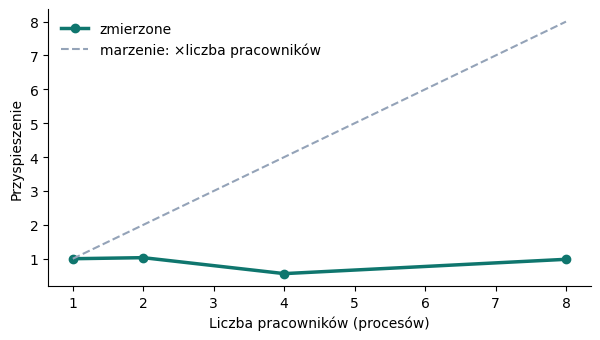

In [5]:
import time, os
from multiprocessing import Pool
import matplotlib.pyplot as plt

PRACA = 24_000_000                       # łączna liczba drobnych kroków do wykonania

def porcja(n):
    s = 0
    for k in range(n):
        s += k * k % 7
    return s

def zmierz(pracownicy):
    t0 = time.perf_counter()
    with Pool(pracownicy) as p:
        p.map(porcja, [PRACA // pracownicy] * pracownicy)
    return time.perf_counter() - t0

wyniki = {}
for k in [1, 2, 4, 8]:
    wyniki[k] = zmierz(k)
    print(f"{k} pracownik(ów): {wyniki[k]:6.2f} s   przyspieszenie ×{wyniki[1] / wyniki[k]:.2f}")

print("\n=== Co mówi o sobie procesor ===")
!lscpu | grep -E "^CPU\(s\)|Thread\(s\) per core|Core\(s\) per socket|Model name"

plt.figure(figsize=(7, 3.6))
plt.plot(list(wyniki), [wyniki[1] / t for t in wyniki.values()], "o-", lw=2.5, color="#0f766e", label="zmierzone")
plt.plot([1, 8], [1, 8], "--", color="#94a3b8", label="marzenie: ×liczba pracowników")
plt.xlabel("Liczba pracowników (procesów)"); plt.ylabel("Przyspieszenie")
plt.legend(frameon=False); plt.gca().spines[["top", "right"]].set_visible(False); plt.show()

**Słowniczek do odczytania wyniku `lscpu`:** *CPU(s)* — liczba procesorów widzianych przez system (vCPU); *Core(s) per socket* — liczba **fizycznych** rdzeni; *Thread(s) per core* — ile wątków sprzętowych przypada na jeden fizyczny rdzeń. Technika, w której jeden fizyczny rdzeń udaje dwa, nazywa się **wielowątkowością współbieżną** (*simultaneous multithreading*, u Intela: *Hyper-Threading*).

**✍️ Odpowiedź** *(proszę kliknąć dwukrotnie tę komórkę i uzupełnić)*

1. Jakie przyspieszenie dało 2, a jakie 8 pracowników? Czy obstawienie było trafne? Dwóch pracowników przyspieszyło pracę około 1,03 raza, natomiast ośmiu pracowników około 0,98 raza. Oznacza to, że zwiększenie liczby pracowników praktycznie nie przyspieszyło pracy. Źle obstawiłem wyniki na początku.
2. Dlaczego 8 pracowników nie pracuje szybciej niż 2? Co robi „nadmiarowych” sześciu? Maszyna posiada tylko 2 procesory logiczne i 1 fizyczny rdzeń. Pozostałe procesy muszą czekać na dostęp do procesora, a system operacyjny przełącza się między nimi. Dodatkowo uruchamianie i zarządzanie wieloma procesami powoduje narzut obliczeniowy.
3. Ile **fizycznych** rdzeni ma ta maszyna, a ile wirtualnych procesorów (vCPU)? Co się kryje pod nazwą „2 vCPU” w cenniku dostawcy chmury? Maszyna posiada 1 fizyczny rdzeń i 2 procesory logiczne (vCPU). Dwa vCPU oznaczają dwa procesory wirtualne udostępnione przez dostawcę chmury, które nie muszą odpowiadać dwóm niezależnym fizycznym rdzeniom.
4. Firma potrzebuje skończyć taką pracę 10 razy szybciej. Co jest w chmurze rozsądniejsze: większa maszyna czy więcej maszyn? Od czego to zależy? To zależy od rodzaju wykonywanej pracy. Jeśli zadanie można podzielić na niezależne części, rozsądniejsze może być wykorzystanie większej liczby maszyn pracujących równolegle. Jeśli zadanie wymaga dużej ilości współdzielonych danych, lepsza może być jedna większa maszyna. Należy również uwzględnić koszty komunikacji i synchronizacji.

<div style="background:linear-gradient(120deg,#be123c,#fb7185);padding:20px 26px;border-radius:14px;color:white;margin-top:18px">
<div style="font-size:13px;letter-spacing:2px;text-transform:uppercase;opacity:.85">Zagadka 4 · regiony i opóźnienia</div>
<div style="font-size:27px;font-weight:700;line-height:1.25;margin-top:4px">⚡ Czy Internet jest szybszy od światła?</div>
</div>


Maszyna Colaba wyśle krótkie „puk-puk” do serwerów AWS w siedmiu regionach świata i zmierzy, po ilu milisekundach usłyszy „kto tam?”. To **czas obiegu** (*round-trip time*, RTT). Potem porównamy go z **granicą fizyczną**: światło w światłowodzie biegnie z prędkością ok. 200 000 km/s, a sygnał musi przebyć drogę tam i z powrotem.

**🎯 Obstawiam** *(proszę uzupełnić **przed** uruchomieniem kodu — bez zaglądania do odpowiedzi!)*

1. Do którego regionu odpowiedź przyjdzie najszybciej, a do którego najwolniej? Najszybciej do Frankfurt a najwolniej do Tokio
2. Ile razy zmierzony czas będzie większy od granicy fizycznej (1×? 2×? 10×?) 2
3. Czy któryś zmierzony czas okaże się **mniejszy** od granicy fizycznej? Nie

In [6]:
import socket, time, json, math, urllib.request

REGIONY = {   # region AWS: (miasto, szerokość, długość geograficzna)
    "eu-central-1":   ("Frankfurt",       50.11,    8.68),
    "us-east-1":      ("Północna Wirginia", 39.04, -77.49),
    "us-west-2":      ("Oregon",          45.84, -119.70),
    "sa-east-1":      ("São Paulo",      -23.55,  -46.63),
    "ap-south-1":     ("Mumbaj",          19.08,   72.88),
    "ap-northeast-1": ("Tokio",           35.68,  139.69),
    "ap-southeast-2": ("Sydney",         -33.87,  151.21),
}

def odleglosc_km(a, b):                       # po powierzchni Ziemi (koło wielkie)
    (f1, l1), (f2, l2) = [(math.radians(x), math.radians(y)) for x, y in (a, b)]
    h = math.sin((f2 - f1) / 2) ** 2 + math.cos(f1) * math.cos(f2) * math.sin((l2 - l1) / 2) ** 2
    return 2 * 6371 * math.asin(math.sqrt(h))

try:
    with urllib.request.urlopen("https://ipinfo.io/json", timeout=10) as o:
        d = json.load(o)
    tu = tuple(map(float, d["loc"].split(",")))
    print(f"Maszyna Colaba stoi w okolicy: {d.get('city')}, {d.get('region')}, {d.get('country')}  {tu}\n")
except Exception:
    tu = (41.26, -95.86)
    print("Nie udało się ustalić położenia — przyjmuję Council Bluffs w stanie Iowa (centrum danych Google).\n")

def rtt_ms(host):
    adres = socket.gethostbyname(host)        # najpierw DNS, żeby nie liczyć go do pomiaru
    najlepszy = float("inf")
    for _ in range(5):
        t0 = time.perf_counter()
        with socket.create_connection((adres, 443), timeout=5):
            pass
        najlepszy = min(najlepszy, (time.perf_counter() - t0) * 1000)
    return najlepszy

print(f"{'Region':<16}{'Miasto':<19}{'Odległość':>10}{'Granica':>10}{'Zmierzono':>11}{'Krotność':>10}")
for region, (miasto, szer, dl) in REGIONY.items():
    km = odleglosc_km(tu, (szer, dl))
    granica = 2 * km / 200_000 * 1000          # ms: tam i z powrotem w światłowodzie
    try:
        t = rtt_ms(f"ec2.{region}.amazonaws.com")
        print(f"{region:<16}{miasto:<19}{km:>8.0f} km{granica:>8.1f} ms{t:>9.1f} ms{t / granica:>9.1f}×")
    except Exception as e:
        print(f"{region:<16}{miasto:<19}{km:>8.0f} km{granica:>8.1f} ms   brak odpowiedzi")

Maszyna Colaba stoi w okolicy: The Dalles, Oregon, US  (45.5946, -121.1787)

Region          Miasto              Odległość   Granica  Zmierzono  Krotność
eu-central-1    Frankfurt              8328 km    83.3 ms    141.5 ms      1.7×
us-east-1       Północna Wirginia      3619 km    36.2 ms     62.6 ms      1.7×
us-west-2       Oregon                  118 km     1.2 ms     12.8 ms     10.9×
sa-east-1       São Paulo             10739 km   107.4 ms    179.0 ms      1.7×
ap-south-1      Mumbaj                12685 km   126.8 ms    212.7 ms      1.7×
ap-northeast-1  Tokio                  7889 km    78.9 ms     95.5 ms      1.2×
ap-southeast-2  Sydney                12449 km   124.5 ms    153.1 ms      1.2×


**✍️ Odpowiedź** *(proszę kliknąć dwukrotnie tę komórkę i uzupełnić)*

1. Gdzie stoi maszyna Colaba? Który region odpowiedział najszybciej, a który najwolniej? Maszyna Google Colab znajduje się w okolicy The Dalles w stanie Oregon w USA. Najszybciej odpowiedział region Oregon (12,8 ms), natomiast najwolniej region Mumbaj (172,0 ms).
2. Jaka była najmniejsza i największa krotność (zmierzony czas / granica fizyczna)? Najmniejsza krotność wyniosła 1,2 raza, a największa 10,9 raza. Największą wartość odnotowano dla regionu Oregon.
3. Proszę podać **trzy powody**, dla których zmierzony czas jest większy od granicy fizycznej. (Wskazówka: czy światłowód biegnie po linii prostej? Co po drodze robią routery?) 1. Światłowody nie biegną po linii prostej, dlatego rzeczywista trasa przesyłania danych jest dłuższa. 2. Routery i przełączniki potrzebują czasu na przetwarzanie i przekazywanie pakietów.3. Występują dodatkowe opóźnienia związane z ruchem sieciowym i oczekiwaniem na dostęp do urządzeń sieciowych.
4. Jeśli któraś krotność wyszła **mniejsza od 1** — czy Internet złamał prawa fizyki? Co mogło być błędne w naszych założeniach? Nie, Internet nie złamał praw fizyki. W moich pomiarach żadna krotność nie była mniejsza od 1. Gdyby tak się stało, mogłoby to oznaczać, że przyjęte współrzędne serwera były niedokładne lub rzeczywista lokalizacja serwera różniła się od podanej.
5. Sklep internetowy obsługuje klientów z Polski. Ile milisekund „traci” każde kliknięcie, jeśli serwer stoi w Sydney zamiast we Frankfurcie? Co z tego wynika dla wyboru regionu? Różnica między nimi to 11,6ms Oznacza to, że Sydney miało o 11,6 ms większe opóźnienie niż Frankfurt. Dla sklepu obsługującego klientów z Polski lepszym wyborem jest Frankfurt, ponieważ znajduje się bliżej klientów i powinien zapewniać mniejsze opóźnienia.

<div style="background:linear-gradient(120deg,#7c3aed,#c084fc);padding:20px 26px;border-radius:14px;color:white;margin-top:18px">
<div style="font-size:13px;letter-spacing:2px;text-transform:uppercase;opacity:.85">Zagadka 5 · przepustowość</div>
<div style="font-size:27px;font-weight:700;line-height:1.25;margin-top:4px">🕊️ Gołąb, samochód czy światłowód?</div>
</div>


Uczelnia chce przenieść **archiwum nagrań wykładów: 100 TB** z Warszawy do centrum danych w Gdańsku (ok. 340 km). Trzy propozycje:

- 🌐 **Światłowód 1 Gb/s** — wykorzystany w 80%.
- 🚗 **Samochód osobowy** z bagażnikiem pełnym dysków SSD — 4 godziny jazdy, plus 2 godziny na pakowanie i rozpakowanie.
- 🕊️ **Gołąb pocztowy** z karteczkami pamięci microSD po 1 TB w woreczku — leci 70 km/h, unosi 5 karteczek naraz.

Brzmi jak żart? W 2009 r. w RPA gołąb z kartą pamięci 4 GB doleciał na odległość ok. 80 km, zanim łącze internetowe zdążyło przesłać choćby niewielką część tych samych danych. A AWS przez lata oferował klientom przewożenie danych ciężarówką z kontenerem pełnym dysków. Informatycy mają na to stare powiedzenie: nie wolno lekceważyć przepustowości samochodu pełnego taśm, pędzącego autostradą.

**🎯 Obstawiam** *(proszę uzupełnić **przed** uruchomieniem kodu — bez zaglądania do odpowiedzi!)*

1. Kto pierwszy dostarczy całe 100 TB: światłowód, samochód czy gołąb (jeden gołąb kursujący tam i z powrotem)? światłowód
2. A kto wygra przy przesyłce **jednego zdjęcia** (5 MB)? światłowód

🌐 Światłowód       277.8 h  =   11.6 dni   efektywna przepustowość:     0.80 Gb/s
🚗 Samochód           6.0 h  =    0.2 dni   efektywna przepustowość:    37.04 Gb/s
🕊️ Gołąb           189.4 h  =    7.9 dni   efektywna przepustowość:     1.17 Gb/s


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127760 (\N{GLOBE WITH MERIDIANS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128663 (\N{AUTOMOBILE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128330 (\N{DOVE OF PEACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


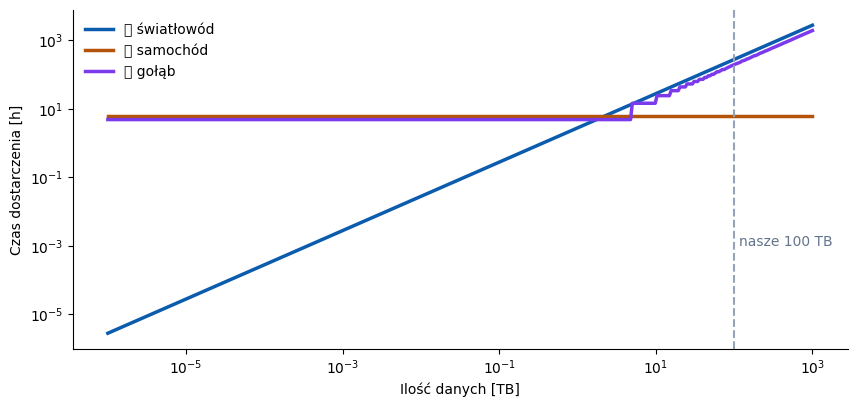

In [7]:
import numpy as np, matplotlib.pyplot as plt

DANE_TB = 100

# --- Światłowód ---
LACZE_GBIT_S, WYKORZYSTANIE = 1.0, 0.8
def swiatlowod_h(tb):
    return tb * 8e12 / (LACZE_GBIT_S * 1e9 * WYKORZYSTANIE) / 3600

# --- Samochód ---
DYSK_TB, DYSKOW_W_BAGAZNIKU = 8, 400        # 400 dysków po 8 TB = 3,2 PB
JAZDA_H, PAKOWANIE_H = 4, 2
def samochod_h(tb):
    kursy = np.ceil(tb / (DYSK_TB * DYSKOW_W_BAGAZNIKU))
    return kursy * (JAZDA_H + PAKOWANIE_H) + (kursy - 1) * JAZDA_H     # między kursami trzeba wrócić

# --- Gołąb ---
TRASA_KM, PREDKOSC_KMH, KARTY_TB = 340, 70, 5
def golab_h(tb):
    loty = np.ceil(tb / KARTY_TB)
    return loty * TRASA_KM / PREDKOSC_KMH + (loty - 1) * TRASA_KM / PREDKOSC_KMH

for nazwa, f in [("🌐 Światłowód", swiatlowod_h), ("🚗 Samochód", samochod_h), ("🕊️ Gołąb", golab_h)]:
    t = float(f(DANE_TB))
    efekt = DANE_TB * 8e12 / (t * 3600) / 1e9
    print(f"{nazwa:<14} {t:9.1f} h  = {t / 24:6.1f} dni   efektywna przepustowość: {efekt:8.2f} Gb/s")

rozmiary = np.logspace(-6, 3, 400)          # od 1 MB do 1000 TB
plt.figure(figsize=(10, 4.4))
plt.loglog(rozmiary, swiatlowod_h(rozmiary), lw=2.5, label="🌐 światłowód", color="#0b5cad")
plt.loglog(rozmiary, samochod_h(rozmiary), lw=2.5, label="🚗 samochód", color="#b45309")
plt.loglog(rozmiary, golab_h(rozmiary), lw=2.5, label="🕊️ gołąb", color="#7c3aed")
plt.axvline(DANE_TB, color="#94a3b8", ls="--"); plt.text(DANE_TB * 1.15, 1e-3, "nasze 100 TB", color="#64748b")
plt.xlabel("Ilość danych [TB]"); plt.ylabel("Czas dostarczenia [h]")
plt.legend(frameon=False); plt.gca().spines[["top", "right"]].set_visible(False); plt.show()

**✍️ Odpowiedź** *(proszę kliknąć dwukrotnie tę komórkę i uzupełnić)*

| Środek transportu | Czas dla 100 TB | Efektywna przepustowość |
|---|---|---|
| 🌐 Światłowód | 277,8h | 0,80Gb/s |
| 🚗 Samochód | 6,0h | 37,04Gb/s |
| 🕊️ Gołąb | 189,4h | 1,17Gb/s |

1. Kto wygrał przy 100 TB, a kto przy jednym zdjęciu (proszę odczytać z wykresu lewą część)? Przy przesyłaniu 100 TB wygrał samochód, który dostarczył dane w 6 godzin. Drugie miejsce zajął gołąb (189,4 godziny), a ostatnie światłowód (277,8 godziny). Przy przesyłaniu jednego zdjęcia o wielkości 5 MB wygrywa światłowód, ponieważ przesłanie małej ilości danych przez Internet jest znacznie szybsze niż fizyczny transport.
2. Od jakiej mniej więcej ilości danych samochód zaczyna wygrywać ze światłowodem? Samochód zaczyna wygrywać przy ilości danych większej niż około 2,16 TB, ponieważ tyle danych światłowód przesyła w ciągu 6 godzin, czyli w czasie potrzebnym samochodowi na dostarczenie dysków.
3. Gołąb ma ogromne **opóźnienie** (godziny), ale całkiem sporą **przepustowość**. Proszę własnymi słowami wyjaśnić różnicę między tymi pojęciami. Co z nich mierzyliśmy w zagadce 4? Opóźnienie określa czas potrzebny na dostarczenie danych do odbiorcy, natomiast przepustowość określa ilość danych, którą można przesłać w jednostce czasu. Gołąb ma duże opóźnienie, ponieważ potrzebuje wielu godzin na dotarcie do celu, ale może jednocześnie przewozić dużą ilość danych. W zagadce 4 mierzyliśmy opóźnienie (RTT).
4. Proszę zmienić `LACZE_GBIT_S` na `10` i uruchomić komórkę ponownie. Co się zmieniło? Dlaczego dostawcy chmury mimo wszystko nadal oferują usługi fizycznego przewozu dysków? Po zwiększeniu przepustowości łącza z 1 Gb/s do 10 Gb/s efektywna przepustowość wzrosła z 0,8 Gb/s do 8 Gb/s. Czas przesłania 100 TB zmniejszył się z 277,8 godziny do około 27,8 godziny. Samochód nadal jest szybszy, ponieważ dostarcza dane w 6 godzin. Dostawcy chmury oferują fizyczny przewóz dysków, ponieważ przy bardzo dużych ilościach danych transport fizyczny może być szybszy i bardziej opłacalny niż przesyłanie przez Internet.

<div style="background:linear-gradient(120deg,#3b0764,#7c3aed);padding:20px 26px;border-radius:14px;color:white;margin-top:18px">
<div style="font-size:13px;letter-spacing:2px;text-transform:uppercase;opacity:.85">Podsumowanie</div>
<div style="font-size:27px;font-weight:700;line-height:1.25;margin-top:4px">Tablica wyników intuicji</div>
</div>

**✍️ Odpowiedź** *(proszę kliknąć dwukrotnie tę komórkę i uzupełnić)*

| Zagadka | Moje obstawienie trafiło? (tak / częściowo / nie) |
|:-:|:-:|
| 1. Kto tu udaje komputer? | częściowo |
| 2. Wyścig liczb pierwszych | częściowo |
| 3. Ilu pracowników? | nie |
| 4. Szybciej od światła? | nie |
| 5. Gołąb, samochód, światłowód | nie |
| **Razem trafień** | **2 / 5** |

Która zagadka najbardziej Państwa zaskoczyła i dlaczego? 5. myślałem, że światłowód mając 200 000 km/h będzie najszybszy we wszystkim.

<div style="background:linear-gradient(120deg,#0f766e,#34d399);padding:20px 26px;border-radius:14px;color:white;margin-top:18px">
<div style="font-size:13px;letter-spacing:2px;text-transform:uppercase;opacity:.85">Zadanie domowe</div>
<div style="font-size:27px;font-weight:700;line-height:1.25;margin-top:4px">Trzy krótkie zadania do wykonania w domu</div>
</div>


**D1. Rewanż urządzeń.** Proszę uruchomić zagadkę 2 na **innym** urządzeniu (telefon, inny komputer, tablet — może należący do kogoś z domowników, za jego zgodą) i dopisać wyniki do tabeli. Które urządzenie wygrało i o ile?

**D2. Moje zdjęcia w chmurze.** Proszę zmierzyć szybkość swojego łącza domowego (np. strona <https://fast.com> — bez logowania; po kliknięciu *Więcej informacji* widać też szybkość wysyłania, *upload*). Następnie proszę oszacować, ile miejsca zajmują Państwa zdjęcia i filmy w telefonie, i obliczyć w nowej komórce:
- ile godzin trwałoby wysłanie ich wszystkich do chmury przez to łącze - trwałoby to 13min 29s ponieważ mam przesyłanie 860Mbps
- ilu gołębi (z zagadki 5) trzeba by wysłać, żeby było szybciej - 1 gołąb i leciałby 5h.

**D3. Do repozytorium.** Gotowy notatnik proszę zapisać w repozytorium `chmura-cwiczenia` z ćwiczeń 1 (*Plik → Zapisz kopię w GitHubie*), z opisem zatwierdzenia `Ćwiczenia 2 — zagadki`.

<div style="background:#e6f4ea;border-left:6px solid #0f766e;padding:12px 16px;border-radius:8px;color:#12303f;font-size:15px;margin:10px 0">📬 <b>Co oddać:</b> adres repozytorium z notatnikiem — w sposób i w terminie podanym przez prowadzącego.</div>